# Telco Churn: Behavior and Financial Analysis

**Purpose:** Quantify the financial exposure from churn and explore how service adoption (add-ons) differs between churned and retained customers.

**Key metric definitions used in this notebook:**
- **ARPU (Average Revenue Per User):** `MonthlyCharges` averaged across a segment. This is what the company billed per customer per month.
- **Historical Billed Value (HBV):** `TotalCharges` as recorded — the total amount billed to a customer over their entire tenure. Already in the data.
- **CLV Proxy:** `MonthlyCharges × tenure`. This *approximates* historical revenue but diverges from `TotalCharges` for new customers (tenure=0, TotalCharges=0). We label it clearly as a proxy, not a true lifetime value prediction.
- **Revenue Exposure:** Sum of `MonthlyCharges` across churned customers — the monthly revenue lost if churned customers are not replaced.

**Causation caveat:** Differences between churned and retained groups are associations, not causes.

## 1. Load data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams["figure.dpi"] = 110

FILE_NAME = "telco_clean.csv"

project_root = next(
    folder
    for folder in [Path.cwd(), *Path.cwd().parents]
    if (folder / "data" / "clean" / FILE_NAME).exists()
)

clean_path = project_root / "data" / "clean" / FILE_NAME
images_dir = project_root / "images"
images_dir.mkdir(exist_ok=True)

df = pd.read_csv(clean_path)
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

# CLV proxy: MonthlyCharges * tenure (historical approximation only)
df["CLV_Proxy"] = df["MonthlyCharges"] * df["tenure"]

print("Loaded from:", clean_path.resolve())
print("Shape:", df.shape)
print("Overall churn rate:", f"{df['ChurnFlag'].mean():.1%}")

Loaded from: D:\telco-churn-analytics\data\clean\telco_clean.csv
Shape: (7043, 24)
Overall churn rate: 26.5%


## 2. Revenue exposure from churn

The most direct financial question: **how much monthly revenue did we lose to churned customers?**

We use `MonthlyCharges` as the revenue proxy — it is what was billed each month. The sum across churned customers gives the monthly run-rate revenue that left with them.

In [2]:
churned = df[df["Churn"] == "Yes"]
retained = df[df["Churn"] == "No"]

total_monthly = df["MonthlyCharges"].sum()
churned_monthly = churned["MonthlyCharges"].sum()
churned_total_billed = churned["TotalCharges"].sum()

print("=== Revenue Exposure Summary ===")
print(f"Total monthly revenue (all customers):   ${total_monthly:,.0f}")
print(f"Monthly revenue from churned customers:  ${churned_monthly:,.0f}")
print(f"  As % of total monthly revenue:         {churned_monthly/total_monthly:.1%}")
print()
print(f"Total historical billed value (churned): ${churned_total_billed:,.0f}")
print(f"  (This is TotalCharges summed across the {len(churned):,} churned customers)")
print()
print("Note: 'Monthly revenue from churned' is the recurring revenue lost per")
print("month if churned customers are not replaced. It is not an annualised figure.")

=== Revenue Exposure Summary ===
Total monthly revenue (all customers):   $456,117
Monthly revenue from churned customers:  $139,131
  As % of total monthly revenue:         30.5%

Total historical billed value (churned): $2,862,927
  (This is TotalCharges summed across the 1,869 churned customers)

Note: 'Monthly revenue from churned' is the recurring revenue lost per
month if churned customers are not replaced. It is not an annualised figure.


## 3. ARPU: average monthly charges by churn label

Churned customers tend to have higher monthly charges. This matters because losing a high-ARPU customer is more financially damaging than losing a low-ARPU one. The box plots and means quantify the gap.

=== ARPU by Churn Label ===
       Mean ARPU  Median ARPU  Std Dev  Customers
Churn                                            
No         61.27        64.43    31.09       5174
Yes        74.44        79.65    24.67       1869

Mean ARPU gap (churned minus retained): $13.18/month


C:\Users\ANKIT KUMAR\AppData\Local\Temp\ipykernel_50400\1323807193.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


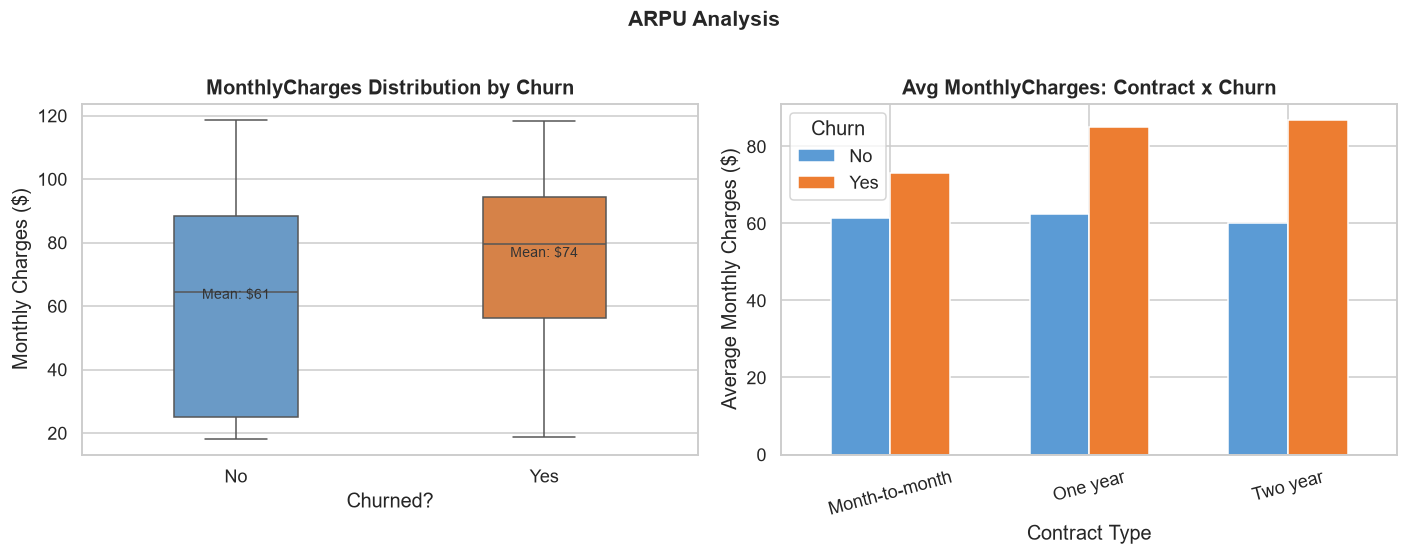

Saved: images/03_01_arpu_analysis.png


In [3]:
arpu_stats = df.groupby("Churn")["MonthlyCharges"].agg(["mean", "median", "std", "count"])
arpu_stats.columns = ["Mean ARPU", "Median ARPU", "Std Dev", "Customers"]
print("=== ARPU by Churn Label ===")
print(arpu_stats.round(2).to_string())
print()
gap = arpu_stats.loc["Yes", "Mean ARPU"] - arpu_stats.loc["No", "Mean ARPU"]
print(f"Mean ARPU gap (churned minus retained): ${gap:.2f}/month")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=df, x="Churn", y="MonthlyCharges",
    order=["No", "Yes"],
    palette={"No": "#5b9bd5", "Yes": "#ed7d31"},
    width=0.4, ax=axes[0],
)
for i, (label, row) in enumerate(arpu_stats.iterrows()):
    axes[0].text(i, row["Mean ARPU"] + 1, f"Mean: ${row['Mean ARPU']:.0f}",
                 ha="center", fontsize=9, color="#333")
axes[0].set_title("MonthlyCharges Distribution by Churn", fontweight="bold")
axes[0].set_xlabel("Churned?")
axes[0].set_ylabel("Monthly Charges ($)")

# ARPU by contract type and churn
contract_arpu = df.groupby(["Contract", "Churn"])["MonthlyCharges"].mean().unstack()
contract_arpu.plot(kind="bar", ax=axes[1], color=["#5b9bd5", "#ed7d31"],
                   edgecolor="white", width=0.6)
axes[1].set_title("Avg MonthlyCharges: Contract x Churn", fontweight="bold")
axes[1].set_xlabel("Contract Type")
axes[1].set_ylabel("Average Monthly Charges ($)")
axes[1].tick_params(axis="x", rotation=15)
axes[1].legend(title="Churn")

fig.suptitle("ARPU Analysis", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(images_dir / "03_01_arpu_analysis.png", bbox_inches="tight")
plt.show()
print("Saved: images/03_01_arpu_analysis.png")

## 4. Historical billed value (CLV proxy) by churn label

We compare two measures of customer lifetime value:
1. **TotalCharges** — actual billed amount in the data
2. **CLV_Proxy** (`MonthlyCharges × tenure`) — an approximation

They should be close for most customers but diverge for new (tenure=0) customers. Churned customers have *lower* TotalCharges because they left earlier — they didn't have as many months to accumulate charges.

=== TotalCharges, CLV Proxy, and Tenure by Churn ===
      TotalCharges          CLV_Proxy          tenure       
              mean   median      mean   median   mean median
Churn                                                       
No         2549.91  1679.52   2549.77  1687.12  37.57   38.0
Yes        1531.80   703.55   1531.61   700.00  17.98   10.0

Note: Churned customers have lower TotalCharges and shorter tenure.
This reflects the fact that they left earlier, not that they paid less per month.
(See ARPU above — churned customers actually paid *more* per month.)


C:\Users\ANKIT KUMAR\AppData\Local\Temp\ipykernel_50400\2040037464.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\ANKIT KUMAR\AppData\Local\Temp\ipykernel_50400\2040037464.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


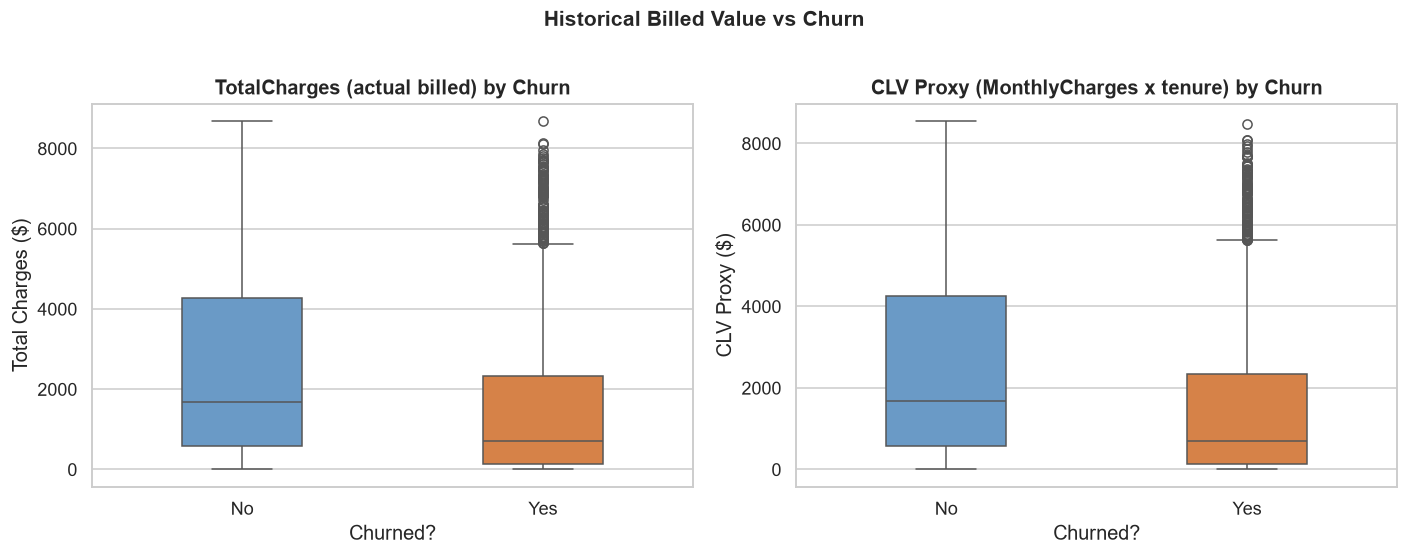

Saved: images/03_02_clv_proxy.png


In [4]:
clv_stats = df.groupby("Churn")[["TotalCharges", "CLV_Proxy", "tenure"]].agg(
    ["mean", "median"]
)
print("=== TotalCharges, CLV Proxy, and Tenure by Churn ===")
print(clv_stats.round(2).to_string())
print()
print("Note: Churned customers have lower TotalCharges and shorter tenure.")
print("This reflects the fact that they left earlier, not that they paid less per month.")
print("(See ARPU above — churned customers actually paid *more* per month.)")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=df, x="Churn", y="TotalCharges",
    order=["No", "Yes"],
    palette={"No": "#5b9bd5", "Yes": "#ed7d31"},
    width=0.4, ax=axes[0],
)
axes[0].set_title("TotalCharges (actual billed) by Churn", fontweight="bold")
axes[0].set_xlabel("Churned?")
axes[0].set_ylabel("Total Charges ($)")

sns.boxplot(
    data=df, x="Churn", y="CLV_Proxy",
    order=["No", "Yes"],
    palette={"No": "#5b9bd5", "Yes": "#ed7d31"},
    width=0.4, ax=axes[1],
)
axes[1].set_title("CLV Proxy (MonthlyCharges x tenure) by Churn", fontweight="bold")
axes[1].set_xlabel("Churned?")
axes[1].set_ylabel("CLV Proxy ($)")

fig.suptitle("Historical Billed Value vs Churn", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(images_dir / "03_02_clv_proxy.png", bbox_inches="tight")
plt.show()
print("Saved: images/03_02_clv_proxy.png")

## 5. Service add-on adoption

The dataset includes six internet-service add-ons: OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies. Each can be "Yes", "No", or "No internet service".

We count how many add-ons each customer has subscribed to (treating "Yes" as 1 and all else as 0). Customers with more add-ons are more embedded in the product, which could lower their likelihood of switching.

**Important:** Customers with no internet service cannot have internet add-ons by definition — their add-on count will always be 0. We note this in the interpretation.

In [5]:
addon_cols = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
]

# Count how many add-ons each customer has (Yes = 1, anything else = 0)
df["AddonCount"] = (df[addon_cols] == "Yes").sum(axis=1)

print("=== Add-on Count Distribution ===")
print(df["AddonCount"].value_counts().sort_index().to_string())
print()
print("=== Average Add-on Count by Churn ===")
print(df.groupby("Churn")["AddonCount"].describe().round(2).to_string())

=== Add-on Count Distribution ===
AddonCount
0    2219
1     966
2    1033
3    1118
4     852
5     571
6     284

=== Average Add-on Count by Churn ===
        count  mean   std  min  25%  50%  75%  max
Churn                                             
No     5174.0  2.14  1.95  0.0  0.0  2.0  4.0  6.0
Yes    1869.0  1.77  1.50  0.0  0.0  2.0  3.0  6.0


=== Churn Rate by Number of Add-ons ===
            customers  churned churn_rate_pct
AddonCount                                   
0                2219      475          21.4%
1                 966      442          45.8%
2                1033      370          35.8%
3                1118      306          27.4%
4                 852      190          22.3%
5                 571       71          12.4%
6                 284       15           5.3%


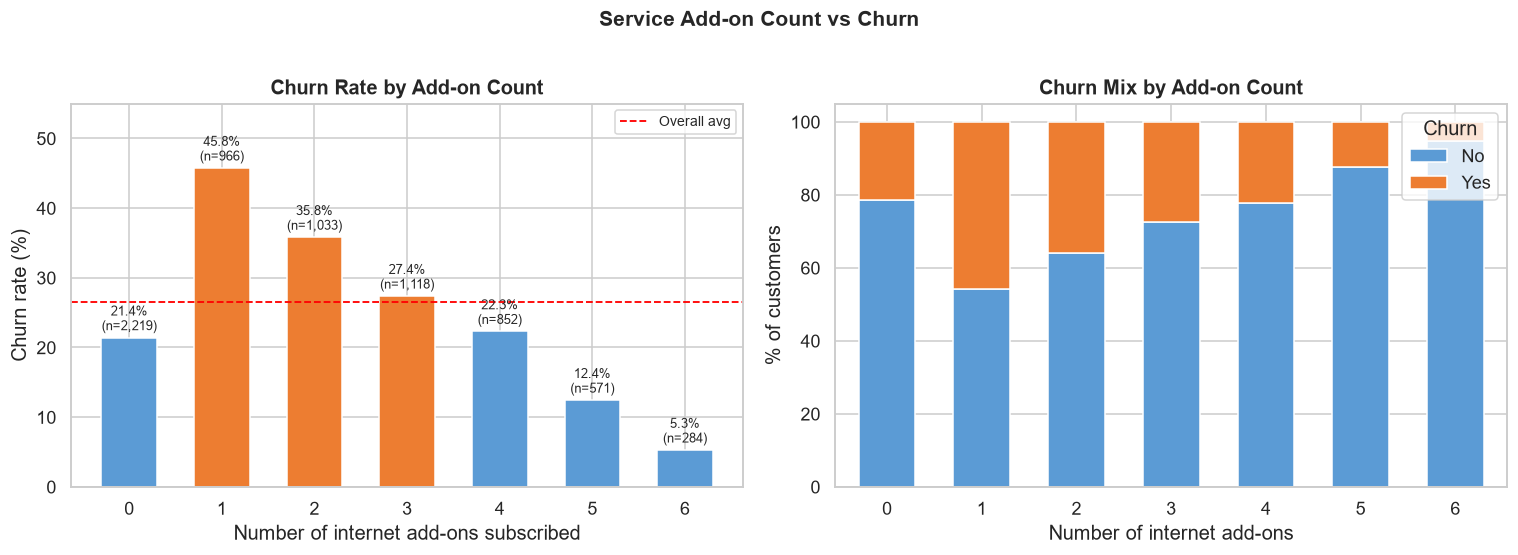

Saved: images/03_03_addon_count_vs_churn.png


In [6]:
# --- Churn rate by add-on count ---
addon_churn = (
    df.groupby("AddonCount")["ChurnFlag"]
    .agg(customers="count", churned="sum")
    .assign(churn_rate=lambda x: x["churned"] / x["customers"])
)
addon_churn["churn_rate_pct"] = addon_churn["churn_rate"].map("{:.1%}".format)
print("=== Churn Rate by Number of Add-ons ===")
print(addon_churn[["customers", "churned", "churn_rate_pct"]].to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: churn rate by add-on count
overall_rate = df["ChurnFlag"].mean() * 100
colors = ["#ed7d31" if r * 100 > overall_rate else "#5b9bd5"
          for r in addon_churn["churn_rate"]]
bars = axes[0].bar(
    addon_churn.index.astype(str),
    addon_churn["churn_rate"] * 100,
    color=colors,
    edgecolor="white",
    width=0.6,
)
for bar, val, cnt in zip(bars, addon_churn["churn_rate"], addon_churn["customers"]):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{val:.1%}\n(n={cnt:,})",
        ha="center", va="bottom", fontsize=8.5,
    )
axes[0].axhline(overall_rate, color="red", linestyle="--", linewidth=1.2, label="Overall avg")
axes[0].set_title("Churn Rate by Add-on Count", fontweight="bold")
axes[0].set_xlabel("Number of internet add-ons subscribed")
axes[0].set_ylabel("Churn rate (%)")
axes[0].set_ylim(0, 55)
axes[0].legend(fontsize=9)

# Right: add-on count distribution split by churn
addon_dist = df.groupby(["AddonCount", "Churn"]).size().unstack(fill_value=0)
addon_dist_pct = addon_dist.div(addon_dist.sum(axis=1), axis=0) * 100
addon_dist_pct.plot(kind="bar", stacked=True, ax=axes[1],
                    color=["#5b9bd5", "#ed7d31"], edgecolor="white", width=0.6)
axes[1].set_title("Churn Mix by Add-on Count", fontweight="bold")
axes[1].set_xlabel("Number of internet add-ons")
axes[1].set_ylabel("% of customers")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Churn", loc="upper right")

fig.suptitle("Service Add-on Count vs Churn", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(images_dir / "03_03_addon_count_vs_churn.png", bbox_inches="tight")
plt.show()
print("Saved: images/03_03_addon_count_vs_churn.png")

## 6. Add-on adoption rates: churned vs retained

For each individual add-on, what fraction of churned vs retained customers subscribed? This tells us which specific services are most strongly associated with retention.

In [7]:
# Adoption rate = % of customers in each churn group who have that add-on set to "Yes"
adoption_rates = {}
for col in addon_cols:
    rates = df.groupby("Churn").apply(
        lambda g: (g[col] == "Yes").mean(), include_groups=False
    )
    adoption_rates[col] = rates

adoption_df = pd.DataFrame(adoption_rates).T
adoption_df.columns = ["Retained", "Churned"]
adoption_df["Gap (Retained - Churned)"] = adoption_df["Retained"] - adoption_df["Churned"]
adoption_df = adoption_df.sort_values("Gap (Retained - Churned)", ascending=False)

print("=== Add-on Adoption Rate: Retained vs Churned ===")
print((adoption_df * 100).round(1).to_string())
print()
print("A positive gap means retained customers adopt this add-on more.")
print("A negative gap means churned customers adopt it more.")

=== Add-on Adoption Rate: Retained vs Churned ===
                  Retained  Churned  Gap (Retained - Churned)
OnlineSecurity        33.3     15.8                      17.5
TechSupport           33.5     16.6                      16.9
OnlineBackup          36.8     28.0                       8.9
DeviceProtection      36.3     29.2                       7.1
StreamingMovies       37.0     43.8                      -6.8
StreamingTV           36.6     43.6                      -7.0

A positive gap means retained customers adopt this add-on more.
A negative gap means churned customers adopt it more.


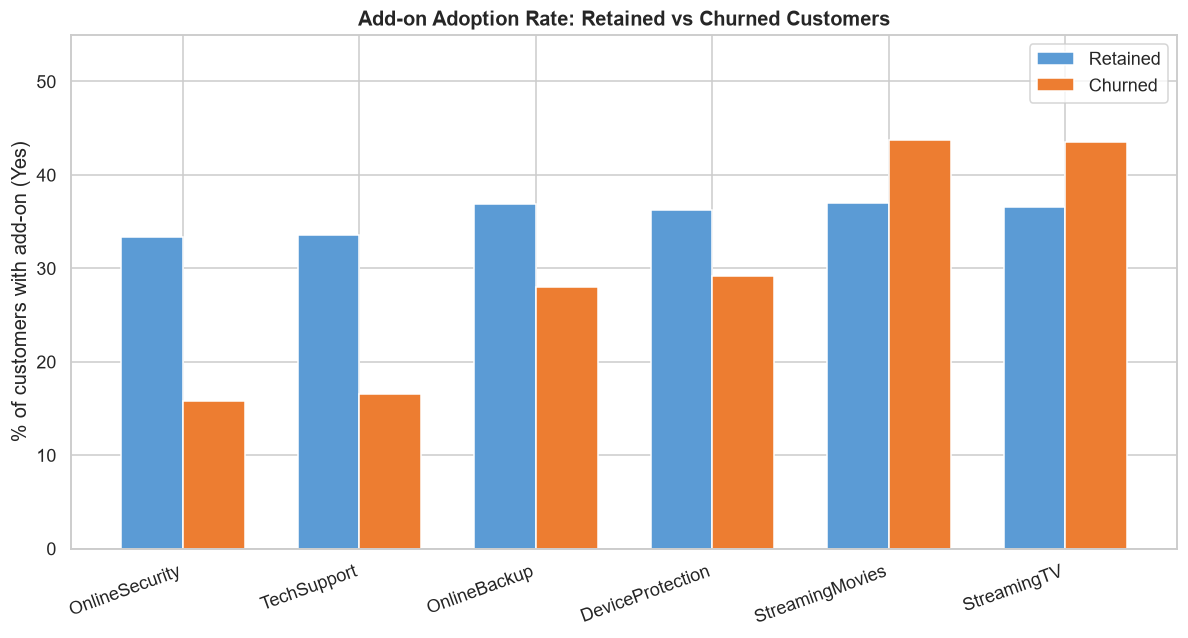

Saved: images/03_04_addon_adoption_comparison.png


In [8]:
fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(adoption_df))
width = 0.35

bars1 = ax.bar(x - width/2, adoption_df["Retained"] * 100, width,
               label="Retained", color="#5b9bd5", edgecolor="white")
bars2 = ax.bar(x + width/2, adoption_df["Churned"] * 100, width,
               label="Churned", color="#ed7d31", edgecolor="white")

ax.set_xticks(x)
ax.set_xticklabels(adoption_df.index, rotation=20, ha="right")
ax.set_title("Add-on Adoption Rate: Retained vs Churned Customers", fontweight="bold")
ax.set_ylabel("% of customers with add-on (Yes)")
ax.set_ylim(0, 55)
ax.legend()

plt.tight_layout()
plt.savefig(images_dir / "03_04_addon_adoption_comparison.png", bbox_inches="tight")
plt.show()
print("Saved: images/03_04_addon_adoption_comparison.png")

## 7. Revenue exposure by contract type

Breaking down revenue exposure by contract type shows where the financial risk is concentrated. Month-to-month churners are more numerous and generate more revenue loss, but their average monthly charges differ from other groups.

=== Monthly Revenue Lost by Contract Type (Churned Customers Only) ===
                churned_customers  monthly_revenue_lost  avg_monthly_charges
Contract                                                                    
Month-to-month               1655             120847.10                73.02
One year                      166              14118.45                85.05
Two year                       48               4165.30                86.78

Total monthly revenue exposure from all churn: $139,131


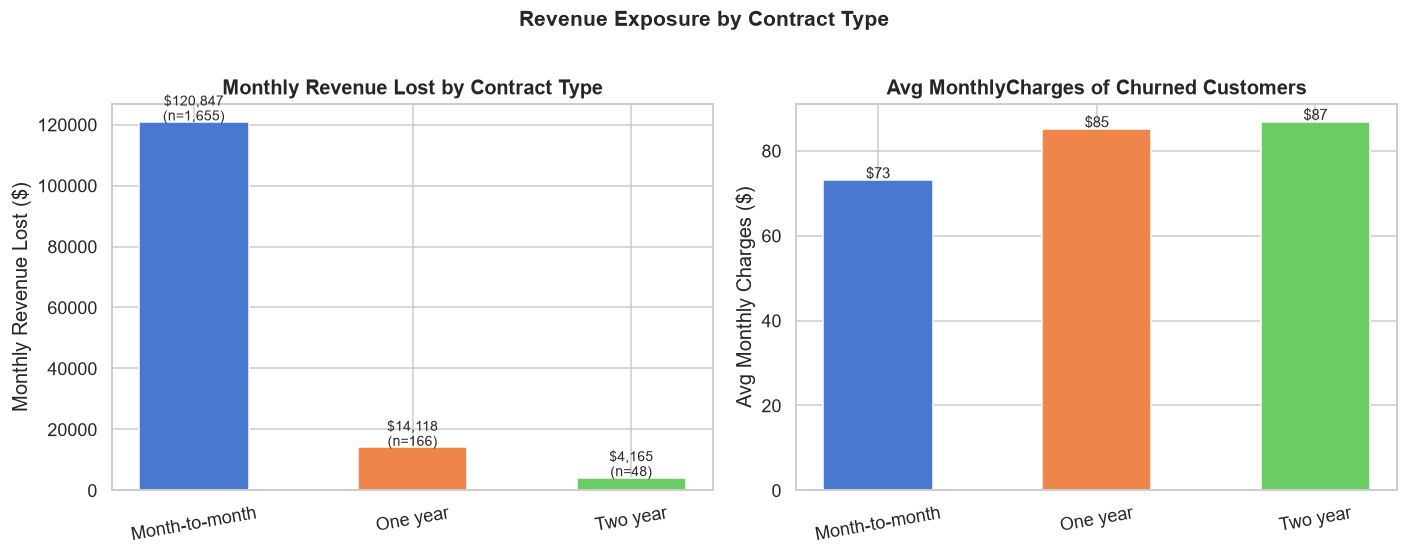

Saved: images/03_05_revenue_exposure_by_contract.png


In [9]:
rev_exposure = (
    df[df["Churn"] == "Yes"]
    .groupby("Contract")["MonthlyCharges"]
    .agg(churned_customers="count", monthly_revenue_lost="sum", avg_monthly_charges="mean")
    .sort_values("monthly_revenue_lost", ascending=False)
)

print("=== Monthly Revenue Lost by Contract Type (Churned Customers Only) ===")
print(rev_exposure.round(2).to_string())
print()
total_lost = rev_exposure["monthly_revenue_lost"].sum()
print(f"Total monthly revenue exposure from all churn: ${total_lost:,.0f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

contract_order = ["Month-to-month", "One year", "Two year"]
plot_data = rev_exposure.reindex(contract_order)

palette = sns.color_palette("muted", 3)
axes[0].bar(plot_data.index, plot_data["monthly_revenue_lost"],
            color=palette, edgecolor="white", width=0.5)
for i, (idx, row) in enumerate(plot_data.iterrows()):
    axes[0].text(i, row["monthly_revenue_lost"] + 500,
                 f"${row['monthly_revenue_lost']:,.0f}\n(n={int(row['churned_customers']):,})",
                 ha="center", fontsize=9)
axes[0].set_title("Monthly Revenue Lost by Contract Type", fontweight="bold")
axes[0].set_ylabel("Monthly Revenue Lost ($)")
axes[0].tick_params(axis="x", rotation=10)

axes[1].bar(plot_data.index, plot_data["avg_monthly_charges"],
            color=palette, edgecolor="white", width=0.5)
for i, (idx, row) in enumerate(plot_data.iterrows()):
    axes[1].text(i, row["avg_monthly_charges"] + 0.5,
                 f"${row['avg_monthly_charges']:.0f}",
                 ha="center", fontsize=10)
axes[1].set_title("Avg MonthlyCharges of Churned Customers", fontweight="bold")
axes[1].set_ylabel("Avg Monthly Charges ($)")
axes[1].tick_params(axis="x", rotation=10)

fig.suptitle("Revenue Exposure by Contract Type", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(images_dir / "03_05_revenue_exposure_by_contract.png", bbox_inches="tight")
plt.show()
print("Saved: images/03_05_revenue_exposure_by_contract.png")

## 8. Financial summary

A clean, printable summary of the financial findings from this notebook.

In [10]:
total_monthly_all = df["MonthlyCharges"].sum()
churned_monthly_loss = df[df["Churn"]=="Yes"]["MonthlyCharges"].sum()
retained_arpu = df[df["Churn"]=="No"]["MonthlyCharges"].mean()
churned_arpu = df[df["Churn"]=="Yes"]["MonthlyCharges"].mean()
churned_total_billed = df[df["Churn"]=="Yes"]["TotalCharges"].sum()
retained_avg_tenure = df[df["Churn"]=="No"]["tenure"].mean()
churned_avg_tenure = df[df["Churn"]=="Yes"]["tenure"].mean()
churned_avg_addons = df[df["Churn"]=="Yes"]["AddonCount"].mean()
retained_avg_addons = df[df["Churn"]=="No"]["AddonCount"].mean()

print("============================================================")
print("  FINANCIAL & BEHAVIOR SUMMARY — Telco Churn")
print("============================================================")
print(f"  Total monthly revenue (all customers): ${total_monthly_all:>10,.0f}")
print(f"  Monthly revenue from churned customers:${churned_monthly_loss:>10,.0f}")
print(f"    -> {churned_monthly_loss/total_monthly_all:.1%} of total monthly revenue")
print()
print(f"  ARPU — Retained customers:             ${retained_arpu:>8.2f}/month")
print(f"  ARPU — Churned customers:              ${churned_arpu:>8.2f}/month")
print(f"    -> Churned ARPU is ${churned_arpu - retained_arpu:.2f} higher")
print()
print(f"  Avg tenure — Retained:                 {retained_avg_tenure:>7.1f} months")
print(f"  Avg tenure — Churned:                  {churned_avg_tenure:>7.1f} months")
print()
print(f"  Avg add-ons — Retained:                {retained_avg_addons:>7.2f}")
print(f"  Avg add-ons — Churned:                 {churned_avg_addons:>7.2f}")
print()
print(f"  Total historical billed (churned):     ${churned_total_billed:>10,.0f}")
print("  (Sum of TotalCharges across churned customers)")
print("============================================================")
print()
print("Interpretation:")
print("- Churned customers paid more per month but stayed for far fewer months.")
print("- They adopted fewer add-on services, suggesting lower product embeddedness.")
print("- The monthly revenue at risk is a meaningful fraction of the total base.")

  FINANCIAL & BEHAVIOR SUMMARY — Telco Churn
  Total monthly revenue (all customers): $   456,117
  Monthly revenue from churned customers:$   139,131
    -> 30.5% of total monthly revenue

  ARPU — Retained customers:             $   61.27/month
  ARPU — Churned customers:              $   74.44/month
    -> Churned ARPU is $13.18 higher

  Avg tenure — Retained:                    37.6 months
  Avg tenure — Churned:                     18.0 months

  Avg add-ons — Retained:                   2.14
  Avg add-ons — Churned:                    1.77

  Total historical billed (churned):     $ 2,862,927
  (Sum of TotalCharges across churned customers)

Interpretation:
- Churned customers paid more per month but stayed for far fewer months.
- They adopted fewer add-on services, suggesting lower product embeddedness.
- The monthly revenue at risk is a meaningful fraction of the total base.
